# Machine Learning textual — o que pode ser automatizado com a evidência disponível?

O Notebook 03 fixou os perfis e os comparadores comerciais. O Notebook 04 acrescentou descrições, 12 aspectos lexicais e leitura assistida de trechos. A FIAP pede evidências sobre atributos valorizados, problemas e oportunidades de investigação. Avaliamos três usos diferentes da automação: organizar leitura por temas, localizar expressões em contexto e preparar uma avaliação semântica independente.

| Tarefa | Unidade e saída | Desenho |
|---|---|---|
| Aspecto | Grupo → múltiplos trechos e assuntos | Quatro famílias históricas, taxonomia N04 e expressões contextuais |
| Objeto | Trecho → produto, componente, acessório, aparelho conectado, logística, instalação ou serviço | Candidato contextual revisável |
| Polaridade | Trecho e aspecto → favorável, desfavorável, mista ou insuficiente | Candidatos locais e abstenção. Nota e perfil entram só na interpretação comercial |
| Macroclassificação | Caminho oficial → macrogrupo auxiliar ou abstenção | Baseline funcional separado, sem reclassificar a dimensão |

## 1 — Reprodução do experimento e das fontes

In [1]:
from pathlib import Path
import os, tempfile, json, platform
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sklearn, scipy
from IPython.display import display
import sys
sys.dont_write_bytecode=True
# Permitir início pela raiz ou pela pasta do notebook, mantendo o módulo local.
pasta_metodos = next((c for p in [Path.cwd(), *Path.cwd().parents]
                      for c in [p, p/'amazon_sales_analise/customer_insights', p/'customer_insights']
                      if (c/'metodos_customer_insights_ml.py').is_file()), None)
if pasta_metodos is not None: sys.path.insert(0, str(pasta_metodos))
from metodos_customer_insights_ml import *
raiz=localizar_raiz();tabelas=ler_tabelas(raiz)
validacoes,contexto_reviews,_=validar_fontes(tabelas,raiz)
corpus,vinculos_textuais,pares_pg,perfis,cobertura=preparar_corpus(tabelas)
visao=agregar_produtos(perfis,pares_pg,corpus)
pares_proximos=similaridade_proxima(corpus)
comp=componentes(corpus,vinculos_textuais,contexto_reviews,pares_proximos.loc[pares_proximos.cosseno.ge(.90)])
destino = os.environ.get("CI_ML_SAIDA")
saida = Path(destino).resolve() if destino else None
if saida is not None:
    assert raiz.parent.resolve() in saida.parents and "backups" in saida.relative_to(raiz.parent.resolve()).parts
    assert saida.name.startswith("EXPERIMENTO_PROVISORIO_ML_")
    saida.mkdir(parents=True,exist_ok=True)
from leitura_dados import ler_canonicas
can = ler_canonicas(raiz)
spec = json.loads((raiz/"documentacao/schema_dados.json").read_text(encoding="utf8"))["entidades"]
for nome,d in can.items():
    ref=spec[nome]
    assert len(d)==ref["linhas"] and d.dtypes.astype(str).to_dict()==ref["tipos"]
    assert d.isna().sum().to_dict()==ref["nulos"] and not d.duplicated(ref["chave"]).any()
    assert d[ref["chave"]].notna().all().all()
assert can["produtos"].categoria_id.isin(can["categorias"].categoria_id).all()
assert len(corpus)==1212 and len(pares_pg)==1370 and len(visao)==1351
assert corpus.grupo_textual_id.is_unique and corpus.sha256_texto.is_unique
assert corpus[["review_title","review_content"]].notna().all().all()
display(pd.Series({k:len(d) for k,d in can.items()},name="Registros").to_frame())
display(cobertura)
print('Grupos únicos:',len(corpus),'| Componentes ampliados:',comp.componente.nunique())
display(corpus[['grupo_textual_id','review_title','review_content']].head(2).assign(review_content=lambda d:d.review_content.str.slice(0,250)+' […]').style.hide(axis='index').set_properties(**{'max-width':'500px','white-space':'normal'}))

,Registros
ocorrencias_base,1465
categorias,211
produtos,1351
usuarios,9050
reviews,9269
vinculos_reviews,11503


,Produtos,Grupos,Ocorrências
perfil_completo,,,
A,212,190,241
Alta/baixa,241,218,253
Ausência,3,3,3
B,299,258,332
Baixa/baixa,330,315,349
Empate,228,190,249
Fora do recorte,38,38,38


Grupos únicos: 1212 | Componentes ampliados: 1181


grupo_textual_id,review_title,review_content
TXT-000001,"Satisfied,Charging is really fast,Value for money,Product review,Good quality,Good product,Good Product,As of now seems good","Looks durable Charging is fine tooNo complains,Charging is really fast, good product.,Till now satisfied with the quality.,This is a good product . The charging speed is slower than the original iPhone cable,Good quality, would recommend,https://m.me […]"
TXT-000002,"A Good Braided Cable for Your Type C Device,Good quality product from ambrane,Super cable,As,Good quality,Good product,its good,Good quality for the price but one issue with my unit",I ordered this cable to connect my phone to Android Auto of car. The cable is really strong and the connection ports are really well made. I already has a Micro USB cable from Ambrane and it's still in good shape. I connected my phone to the car usin […]


### A.1 — Preparação do experimento, sem ocultar perdas
Originais integrais permanecem no corpus. A versão de busca usa NFC, espaços e máscara aproximada de URLs como no baseline; sem remoção de negações ou tradução. TF-IDF usa palavras e bigramas, mínimo de três grupos, máximo de 85% do corpus e até 10 mil termos. Stopwords inglesas excluem **no/not/nor/never** da remoção. Essa representação pode perder marcas combinantes e idiomas pouco frequentes; não é uma solução multilíngue validada.

NMF decompõe pesos não negativos em combinações de temas. Normalizamos a escala dos componentes antes de comparar pesos. Peso relativo é participação no vetor de temas do bloco, **não probabilidade de sentimento nem confiança calibrada**. Blocos sem vocabulário abstêm; peso máximo<0,35 ou diferença entre dois maiores<0,10 sinaliza ambiguidade. Os limiares são heurísticos, com sensibilidade exibida, não validados em rótulos.

In [2]:
baseline=corpus[list(REGRAS)].sum().rename('Grupos com expressão').to_frame()
baseline['Denominador']=len(corpus)
display(baseline)
resultado=experimentar_temas(corpus,comp)
display(resultado['metricas'].round(4))
print('Dimensão TF-IDF:',resultado['x'].shape)
print('Grupos sem representação:',int((resultado['x'].getnnz(axis=1)==0).sum()))

,Grupos com expressão,Denominador
Charging/charger (candidato),238,1212
Bateria,232,1212
Som e áudio,224,1212
Referência a value for money,479,1212
Referência a facilidade de uso/instalação/limpeza,357,1212


,k,semente,erro_reconstrucao,iteracoes,menor_tema,maior_tema,diversidade_top10,maior_cosseno_entre_temas
0,6,42,33.5157,123,89,366,0.9000,0.3831
1,6,7,33.5157,124,89,365,0.9000,0.3831
2,6,99,33.5157,124,89,366,0.9000,0.3831
3,10,42,33.2479,74,62,180,0.9200,0.3512
4,10,7,33.2479,71,62,181,0.9200,0.3515
5,10,99,33.2479,74,62,180,0.9200,0.3512
6,14,42,33.0226,138,6,164,0.9071,0.3219
7,14,7,33.0274,88,6,157,0.8714,0.3225
8,14,99,33.0279,104,6,160,0.8929,0.3180


Dimensão TF-IDF: (1212, 10000)
Grupos sem representação: 0


## B — Temas aprendidos e estabilidade
Erro de reconstrução menor com mais componentes é esperado; não mede correção semântica. Diversidade dos dez termos principais e redundância por cosseno ajudam a identificar tópicos repetidos. ARI compara atribuições predominantes ignorando a numeração dos tópicos; alinhamento por maior cosseno compara vetores. A estabilidade é calculada no mesmo snapshot, incluindo documentos usados nos ajustes; não representa desempenho fora da amostra.

,Perturbação,semente,grupos_ajuste,cosseno_temas_alinhados,ARI_atribuicao_global
0,Semente; mesmo corpus/vocabulário,7,1212,1.0000,0.9976
1,Semente; mesmo corpus/vocabulário,99,1212,1.0000,1.0000
2,80% componentes; TF-IDF reajustado,42,967,0.8730,0.8452
3,80% componentes; TF-IDF reajustado,7,969,0.8942,0.7256
4,80% componentes; TF-IDF reajustado,99,967,0.8915,0.6934
5,Sem sete termos genéricos,42,1212,0.8250,0.5144


Tema,Termos principais,Grupos dominantes,Grupos sem abstenção
T01,"easy, easy use, use, clean, easy clean, cleaning, product easy, machine, handy, make, coffee, power",180,141
T02,"cable, charging, fast, fast charging, charger, usb, charge, charging cable, cable good, durable, original, data",154,126
T03,"sound, bass, sound quality, ear, earphones, music, quality, noise, good sound, mic, earphone, ears",87,81
T04,"value, value money, money, nice, good product, nice product, product good, good good, money good, price, product nice, product value",173,128
T05,"tv, picture, picture quality, sound, smart, service, quality, tv good, smart tv, installation, hdmi, good tv",66,59
T06,"watch, battery, phone, features, battery life, life, camera, screen, smart watch, touch, app, days",93,75
T07,"mouse, keyboard, gaming, laptop, smooth, keys, good mouse, click, typing, use, wireless, using",84,64
T08,"remote, working, original, not working, not, works, tv, buttons, fine, button, working fine, original remote",62,48
T09,"water, heater, heating, hot, installation, room, heat, geyser, hot water, temperature, no, not",146,107
T10,"quality, good quality, sturdy, not, stand, cover, material, price, worth, quality good, little, quality product",167,124


,peso_minimo,margem_minima,grupos_sem_abstencao
0,0.25,0.05,1095
1,0.35,0.10,953
2,0.45,0.15,809


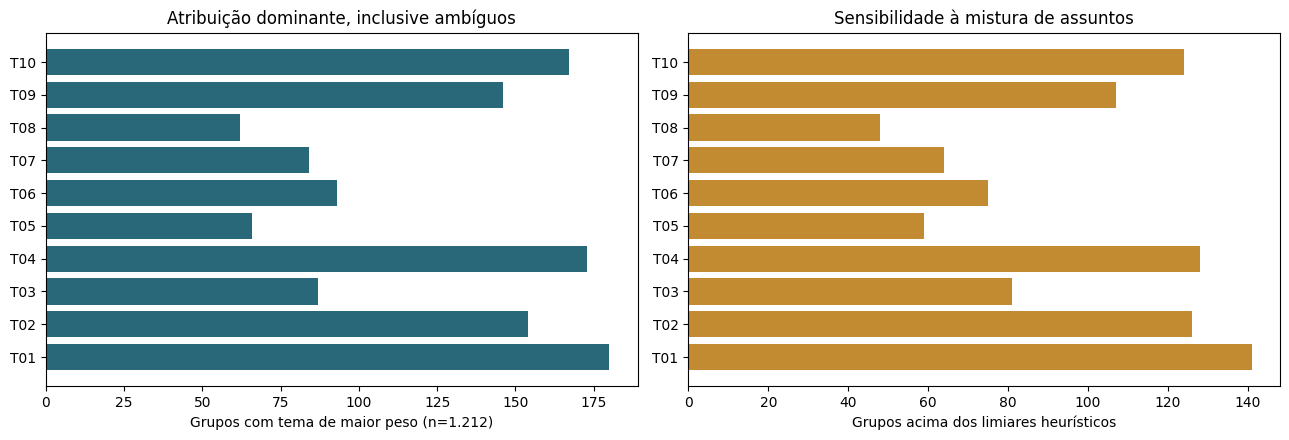

In [3]:
display(resultado['estabilidade'].round(4))
display(resultado['temas'].style.hide(axis='index').set_properties(**{'max-width':'600px','white-space':'normal'}))
display(resultado['limiares'])
fig,axes=plt.subplots(1,2,figsize=(13,4.5))
t=resultado['temas']
axes[0].barh(t.Tema,t['Grupos dominantes'],color='#286879');axes[0].set_xlabel('Grupos com tema de maior peso (n=1.212)');axes[0].set_title('Atribuição dominante, inclusive ambíguos')
axes[1].barh(t.Tema,t['Grupos sem abstenção'],color='#c28b32');axes[1].set_xlabel('Grupos acima dos limiares heurísticos');axes[1].set_title('Sensibilidade à mistura de assuntos')
plt.tight_layout();plt.show()

Com k=10, os temas dominantes têm 62–180 grupos; k=6 concentra até 366 e k=14 cria tema de apenas seis. A resolução intermediária é útil para leitura, sem comprovar que dez seja o número verdadeiro de temas. A estabilidade entre sementes é alta (ARI 0,998–1,000), mas cai nas subamostras por componente (0,693–0,845) e ao retirar sete termos genéricos (0,514). Logo, inicialização estável não implica estrutura semântica definitiva.

Dos 1.212 grupos, 259 são ambíguos pelos limiares adotados; 953 ficam acima deles. Ao variar peso/margem, essa quantidade muda de 809 a 1.095. Não se interpreta 953 como classificações corretas. Temas de áudio, cabos, TV e periféricos refletem em grande parte o tipo de produto; value/money e quality são mais genéricos. A diversidade dos termos (0,92) tampouco valida polaridade.

### B.1 — Exemplos fortes, centrais e fracos
Para cada tema, exportamos dois maiores pesos, um caso central e o menor peso entre seus dominantes. A prévia mostra os primeiros dois temas, com corte sinalizado; todos os exemplos integrais são salvos. A inspeção analítica assistida não é anotação humana independente nem cálculo de precisão.

In [4]:
exemplos=resultado['exemplos'].copy()
exemplos['Prévia explicitamente truncada']=exemplos['Texto integral'].str.slice(0,460)+' […]'
display(exemplos.loc[exemplos.Tema.isin(['T01','T02']),['Tema','Critério','grupo_textual_id','Peso relativo','Prévia explicitamente truncada']].style.hide(axis='index').format(precision=3).set_properties(**{'max-width':'560px','white-space':'normal'}))
atribuicoes=resultado['atribuicoes']
diagnostico_escrita=atribuicoes.merge(corpus[['grupo_textual_id','triagem_escrita','caracteres']],on='grupo_textual_id',validate='one_to_one')
display(diagnostico_escrita.groupby('triagem_escrita').agg(Grupos=('grupo_textual_id','size'),Ambiguos=('situacao',lambda s:s.eq('Ambíguo').sum()),Peso_mediano=('peso_relativo_max','median'),Caracteres_medianos=('caracteres','median')).round(3))

Tema,Critério,grupo_textual_id,Peso relativo,Prévia explicitamente truncada
T01,Maior peso,TXT-001251,1.000,"Heats up,I just bought this product and my review based on my previous purchases are my in laws home,Easy to use,Nicee,Good product,Nice product..,Very Easy to use,Powerful Blender with 3in1 attachments It's very easy to use. And easy to clean. It does it's jób as described. Only drawback is that, the motor unit heats up v very quickly🥵, even with very little use. I have only used this product twice so far, so I can't speak for its durability. Also the pri […]"
T01,Segundo peso,TXT-001451,0.959,"Easy To Carry,Nice product,Handy and easy to use,Best,Very easy to make waffle. Best product from Amazon,easy to make,Disappointed,Very gud n very easy make waffers I love it this produt Really Easy to carry and to make waffle in it at a reasonable price,The product is really good...small in size and very easy to use..easy to clean,Very easy to use waffle maker i have small kitchen so this one was best for me its ready to use within 4 min and waffles takes […]"
T01,Central,TXT-001181,0.521,"Easy to use. Does its job..,Easy to carry now,Doing the job right,Good product initially,Good product for kitchen use,Great item user friendly,Good enough,Good quality https://m.media-amazon.com/images/W/WEBP_402378-T1/images/I/61JhAq4j0qL._SY88.jpg,I like this product,The product is good ..my only complaint is regarding the cells..along with the machine, the cell were sent separately which were of no use..i had to purchase them separately,When I bought it […]"
T01,Menor peso,TXT-000949,0.191,"Helpful product for students,Nice Product,Very good to write and erased,quite bright but have an excessive thick pointer which makes screen to fill up quick,Good product, struggling with erase button,it takes pressure also,Value for money,Its validity When I open the box and unlock the erase button and try to erase things...but that time it not erasing...but after some time when I press it again and again then it erases miracles But this LCD screen fell sc […]"
T02,Maior peso,TXT-000035,1.000,"The metal pin is losing it's strength,Sahi h bs 44 rupe ki and dilivery charge 40,Good Charging cable,Good sturdy micro usb cable with good charging speeds,Cheapest micro USB cable in the market,boat is better than this,I bought this for 199rs best charging cable for all mobiles,Good It's a good data cable and I recommend it to purchase,the only issue was the metal pin is not fixed firmly so it has become loose,otherwise no issue,must purchase,https://m.me […]"
T02,Segundo peso,TXT-000286,1.000,"The metal pin is losing it's strength,Sahi h bs 44 rupe ki and dilivery charge 40,Good Charging cable,Good sturdy micro usb cable with good charging speeds,Cheapest micro USB cable in the market,boat is better than this,I bought this for 199rs best charging cable for all mobiles,Good It's a good data cable and I recommend it to purchase,the only issue was the metal pin is not fixed firmly so it has become loose,otherwise no issue,must purchase,https://m.me […]"
T02,Central,TXT-000484,0.656,"Nice one,Nice 👍 I'm happy,Best buy in the reasonable price,Great product,product review MI charger!!,MI mobile charger,Top quality charger. Original MI brand. Do buy it if you need a B type charge,Good charger Ordinary,Nice pic 👍 I'm happy,Its original mi charger which gives a fast and smooth charging.,Great product,i'm using it for 2 weeks now. No issues with the product. I am satisfied with the product.thank you.,MI Mobile chagerWire & adopter ki quality […]"
T02,Menor peso,TXT-000584,0.210,"Quite Good,good pencil,Value for money,Brilliant,Value for moeny product,Must to buy this pencil,Problemsolver,It works as advertised After 10 days of use bhaut acha chl rha ha and I will review again aapko bata dunga kessa ha Thoda time BaadBut Product acha ha Abhi tak kuch kharab nahi hua and mene bhe isska khayal rakha ha,pencil is good working good but build could be better,Excellent experienc

,Grupos,Ambiguos,Peso_mediano,Caracteres_medianos
triagem_escrita,,,,
Escrita índica presente; idioma não confirmado,57,10,0.594,597.0
Sem escrita índica detectada; idioma não confirmado,1155,249,0.565,801.0


## C — O que os temas acrescentam aos perfis
Cada produto conta uma vez por tema predominante em pelo menos um de seus grupos. Temas podem coexistir entre grupos de um produto; percentuais não são aditivos. Incluímos os dominantes mesmo em blocos ambíguos **apenas para diagnóstico**, e calculamos cobertura à parte. Comparamos caminhos completos com n≥5 por perfil e B; o piso é descritivo. Ainda pode haver mistura de especificações e texto compartilhado. Nenhum resultado de tema é aprovado como KPI de reclamação.

In [5]:
pg_temas=pares_pg.merge(atribuicoes,on='grupo_textual_id',validate='many_to_one')
matriz=pd.crosstab(pg_temas.product_id,pg_temas.tema_dominante).gt(0)
prod_modelo=perfis[['product_id','categoria_nivel_1','categoria_nivel_2','category_original','perfil_completo']].merge(matriz,on='product_id',validate='one_to_one')
prod_modelo['grupos_sem_abstencao']=prod_modelo.product_id.map(pg_temas.assign(ok=~pg_temas.situacao.isin(['Ambíguo','Sem vocabulário'])).groupby('product_id').ok.sum()).astype(int)
linhas=[]
for caminho,d in prod_modelo.groupby('category_original'):
    for perfil in ['A','Alta/baixa']:
        a=d.loc[d.perfil_completo.eq(perfil)];b=d.loc[d.perfil_completo.eq('B')]
        if min(len(a),len(b))<5:continue
        for tema in matriz.columns:linhas.append({'Caminho':caminho,'Perfil':perfil,'Tema':tema,'n perfil':len(a),'n B':len(b),'Produtos tema perfil':int(a[tema].sum()),'Produtos tema B':int(b[tema].sum()),'Diferença pp':100*(a[tema].mean()-b[tema].mean())})
contrastes_modelo=pd.DataFrame(linhas)
display(contrastes_modelo.sort_values(['n perfil','n B'],ascending=False).head(10).style.hide(axis='index').format(precision=2).set_properties(**{'max-width':'400px','white-space':'normal','overflow-wrap':'anywhere','word-break':'break-word'}))
from sklearn.metrics import normalized_mutual_info_score
grupos_categoria=vinculos_textuais[['grupo_textual_id','product_id']].drop_duplicates().merge(perfis[['product_id','categoria_nivel_1','categoria_nivel_2']],on='product_id',validate='many_to_one').drop_duplicates('grupo_textual_id')
alinhado=atribuicoes.merge(grupos_categoria,on='grupo_textual_id',validate='one_to_one')
print('NMI tema/categoria principal, descritivo:',round(normalized_mutual_info_score(alinhado.tema_dominante,alinhado.categoria_nivel_1),4))
print('NMI tema/nível 2, descritivo:',round(normalized_mutual_info_score(alinhado.tema_dominante,alinhado.categoria_nivel_1+' / '+alinhado.categoria_nivel_2),4))
assert prod_modelo.product_id.is_unique and len(prod_modelo)==1351

Caminho,Perfil,Tema,n perfil,n B,Produtos tema perfil,Produtos tema B,Diferença pp
Computers&Accessories|Accessories&Peripherals|Cables&Accessories|Cables|USBCables,Alta/baixa,T01,32,22,0,0,0.00
Computers&Accessories|Accessories&Peripherals|Cables&Accessories|Cables|USBCables,Alta/baixa,T02,32,22,32,21,4.55
Computers&Accessories|Accessories&Peripherals|Cables&Accessories|Cables|USBCables,Alta/baixa,T03,32,22,0,0,0.00
Computers&Accessories|Accessories&Peripherals|Cables&Accessories|Cables|USBCables,Alta/baixa,T04,32,22,0,0,0.00
Computers&Accessories|Accessories&Peripherals|Cables&Accessories|Cables|USBCables,Alta/baixa,T05,32,22,0,0,0.00
Computers&Accessories|Accessories&Peripherals|Cables&Accessories|Cables|USBCables,Alta/baixa,T06,32,22,0,0,0.00
Computers&Accessories|Accessories&Peripherals|Cables&Accessories|Cables|USBCables,Alta/baixa,T07,32,22,0,0,0.00
Computers&Accessories|Accessories&Peripherals|Cables&Accessories|Cables|USBCables,Alta/baixa,T08,32,22,0,1,-4.55
Computers&Accessories|Accessories&Peripherals|Cables&Accessories|Cables|USBCables,Alta/baixa,T09,32,22,0,0,0.00
Computers&Accessories|Accessories&Peripherals|Cables&Accessories|Cables|USBCables,Alta/baixa,T10,32,22,0,0,0.00


NMI tema/categoria principal, descritivo: 0.3493
NMI tema/nível 2, descritivo: 0.4699


O NMI descritivo tema/categoria principal é 0,349 e tema/nível 2 é 0,470. Esses valores, junto dos termos de TV, cabos, teclados e aquecimento, mostram que a estrutura aprendida acompanha função comercial; não identifica automaticamente problemas que distinguem A de B. Os contrastes locais servem para selecionar leitura, não para rotular grupos como favoráveis/desfavoráveis.

**Caso contrário decisivo:** TXT-000325 recebe T09 (aquecimento) com peso relativo 0,521, mas o texto diz apenas que houve boa entrega/embalagem e o produto acabou de ser aberto. Nem o limiar de peso nem a dominância comprovam assunto sustentado. TXT-000757 é roteador com T05/TV e peso 0,275; este fica ambíguo. A ausência de gold impede estimar precisão global; registrar estes erros não é anotação humana independente.

### C.1 — Baseline versus temas e falhas concretas
A tabela de sobreposição conta grupos dominantes que contêm a expressão; não é precisão/recall contra verdade. O baseline é explícito e estreito; NMF amplia o vocabulário, mas também produz associações genéricas e indevidas. Os casos abaixo são interpretações assistidas e revisáveis, não rótulos gold.

In [6]:
sobreposicao=atribuicoes.merge(corpus[['grupo_textual_id']+list(REGRAS)],on='grupo_textual_id',validate='one_to_one').groupby('tema_dominante')[list(REGRAS)].sum()
sobreposicao.insert(0,'Grupos dominantes',atribuicoes.tema_dominante.value_counts())
display(sobreposicao.rename(columns={'Charging/charger (candidato)':'Charging/charger','Referência a value for money':'Value for money','Referência a facilidade de uso/instalação/limpeza':'Easy to use/install/clean'}))
casos_criticos=atribuicoes.loc[atribuicoes.grupo_textual_id.isin(['TXT-000325','TXT-000757','TXT-000017','TXT-000252'])].merge(corpus[['grupo_textual_id','review_title','review_content']],on='grupo_textual_id',validate='one_to_one')
display(casos_criticos[['grupo_textual_id','tema_dominante','situacao','peso_relativo_max','review_title']].style.hide(axis='index').format(precision=3).set_properties(**{'max-width':'540px','white-space':'normal'}))
print('TXT-000325 — texto integral:',corpus.set_index('grupo_textual_id').loc['TXT-000325','review_content'])

,Grupos dominantes,Charging/charger,Bateria,Som e áudio,Value for money,Easy to use/install/clean
tema_dominante,,,,,,
T01,180,14,27,10,47,145
T02,154,129,18,4,65,14
T03,87,24,40,85,33,2
T04,173,10,8,8,119,48
T05,66,2,1,53,34,5
T06,93,33,73,31,30,6
T07,84,5,32,15,33,23
T08,62,2,20,4,18,3
T09,146,5,7,9,46,69


grupo_textual_id,tema_dominante,situacao,peso_relativo_max,review_title
TXT-000017,T05,T05,0.957,"It is the best tv if you are getting it in 10-12k,Good price but the OS lags,GARBAGE QUALITY,Good product.,Good quality,Great experience everything is fantastic 🤠,Super picture quality and sound quality,Awesome"
TXT-000252,T08,T08,0.983,"Netflix button not working others works well,Good,Compatible with Vu Premium TV,Not like the original one.. but not bad.,Not Good Quality,Working fine,Half of the button doesn’t work,Hardness"
TXT-000325,T09,T09,0.521,Awesome Product
TXT-000757,T05,Ambíguo,0.275,"Con = no bandwidth control,Setup is smooth and easy,Good coverage,as money as goods,The signal reach could be better,overall is ok,Product,Class product from TP-Link! A worthy investment."


TXT-000325 — texto integral: Quick delivery.Awesome ProductPacking was goodJust opened the productExcited to you it


A inspeção sustenta apenas nomes provisórios: T01 uso/limpeza; T02 cabos/carga; T03 áudio; T04 valor/genéricos; T05 TV/imagem/serviço; T06 relógios/telefones; T07 mouse/teclado; T08 controles/funcionamento; T09 aquecimento/água; T10 qualidade/material genéricos. Não substituímos IDs por nomes que aparentem validação humana.

TXT-001251 (T01) mistura facilidade com aquecimento do motor; TXT-000035 (T02) mistura carga com pino frouxo; TXT-000017 (T05) mistura imagem/áudio favoráveis com travamento e serviço; TXT-000252 (T08) combina compatibilidade com botões que não funcionam. São perguntas úteis para a taxonomia de aspectos, não prevalências. A aprovação de KPI textual automático fica recusada nesta entrega; o experimento continua disponível para auditoria e seleção de casos.

## 2 — Expressões contextuais: que evidência conseguimos localizar?

In [7]:
taxonomia_n04 = {'Funcionamento': '\\b(?:working|works?|stopped|faulty|malfunction)\\b', 'Acabamento': '\\b(?:build quality|material quality|finish|scratch(?:es)?|stains?)\\b', 'Durabilidade': '\\b(?:durab\\w*|sturdy|broke|breaks?|stopped working)\\b', 'Compatibilidade': '\\b(?:compatib\\w*|usb[- ]?[ac]|micro[- ]?(?:usb|b)|lightning|3\\.5\\s*mm)\\b', 'Conectividade': '\\b(?:connect\\w*|bluetooth|wi-?fi|pairing|sync\\w*)\\b', 'Áudio e chamadas': '\\b(?:sound|audio|bass|mic|microphone|calls?|volume)\\b', 'Autonomia e carga': '\\b(?:battery|batteries|charg(?:e[rs]?|ing)|mah)\\b', 'Uso e conforto': '\\b(?:easy to use|comfort\\w*|fitting|fit|keypad|weight)\\b', 'Instalação e manutenção': '\\b(?:install\\w*|cleaning|easy to clean|maintenance|cartridge|filter replacement)\\b', 'Preço e valor': '\\b(?:value for money|worth (?:for )?(?:the )?money|worth the price|not worth|budget|price)\\b', 'Entrega e embalagem': '\\b(?:deliver\\w*|packag\\w*|packed|courier)\\b', 'Atendimento': '\\b(?:customer (?:care|service|support)|service (?:person|cent[er]+|request)|good service|after[- ]sales)\\b'}
leitura_n04 = [('B01LONQBDG', 'Conectores e sincronização', 'cabo', 'Anunciado', 'about_product', 'Offers reliable connectivity for easy charging or syncing'), ('B01LONQBDG', 'Compatibilidade', 'cabo e telefones', 'Favorável', 'review_content', 'You can easily transfer files between two android phones, one with micro USB port and the other with USB C.'), ('B01LONQBDG', 'Acabamento', 'cabo', 'Desfavorável', 'review_content', 'it had yellow stains on it'), ('B01LONQBDG', 'Espessura', 'cabo', 'Desfavorável', 'review_content', 'The cable could have been thicker.'), ('B071SDRGWL', 'Durabilidade e sincronização', 'cabo', 'Anunciado', 'about_product', 'Support The Maximum 3A Fast Charging And The Speed Of Data Sync Up To 480 Mbps'), ('B071SDRGWL', 'Durabilidade', 'cabo', 'Anunciado', 'about_product', 'For Reinforcement And Added Durability'), ('B071SDRGWL', 'Durabilidade', 'cabo', 'Favorável', 'review_content', 'it almost last three years post heavy usage'), ('B071SDRGWL', 'Carregamento', 'cabo e aparelho', 'Favorável', 'review_content', 'enables Fast Charging for Samsung M21 as well as M33 5G 24 W seeking phones'), ('B071SDRGWL', 'Comprimento', 'variante do cabo', 'Insuficiente', 'review_content', '2 metre cable length helpful'), ('B07JQKQ91F', 'Graves', 'fone', 'Anunciado', 'about_product', 'High Clean Bass'), ('B07JQKQ91F', 'Conforto', 'fone', 'Anunciado', 'about_product', 'Lightweight and comfortable'), ('B07JQKQ91F', 'Encaixe', 'fone', 'Favorável', 'review_content', 'Fitting in ear is perfect'), ('B07JQKQ91F', 'Graves', 'fone', 'Desfavorável', 'review_content', 'the bass was not up to mark'), ('B07JQKQ91F', 'Durabilidade', 'fone', 'Insuficiente', 'review_content', "I can't comment on its durability"), ('B07JQKQ91F', 'Funcionamento', 'fone', 'Desfavorável', 'review_content', 'Unable to hear after, 8 months'), ('B01F25X6RQ', 'Conexão', 'fone', 'Anunciado', 'about_product', 'Headphone Jack: 3.5mm'), ('B01F25X6RQ', 'Som', 'fone', 'Favorável', 'review_content', 'The sound quality is excellent for the price'), ('B01F25X6RQ', 'Material', 'fone', 'Desfavorável', 'review_content', "the material quality isn't good"), ('B01F25X6RQ', 'Microfone', 'fone', 'Favorável', 'review_content', 'mic works well during the call.'), ('B01F25X6RQ', 'Graves', 'fone', 'Desfavorável', 'review_content', 'Less bass'), ('B01F25X6RQ', 'Graves', 'fone', 'Favorável', 'review_content', 'Treble and bass are balanced well.'), ('B076VQS87V', 'Potência e cabo', 'ferro', 'Anunciado', 'about_product', 'Swivel Cord, Dry Iron 1000W'), ('B076VQS87V', 'Cabo', 'ferro', 'Desfavorável', 'review_content', 'Cord is too short'), ('B076VQS87V', 'Uso', 'ferro', 'Favorável', 'review_content', 'Like the product great quality and easy to use'), ('B076VQS87V', 'Peso', 'ferro', 'Favorável', 'review_content', 'Light weight working good'), ('B076VQS87V', 'Acabamento', 'ferro', 'Desfavorável', 'review_title', 'There was one scratch on the surface which was hide under the sticker'), ('B009P2L7CO', 'Peso e uso', 'ferro', 'Anunciado', 'about_product', 'Heavy weight iron for easy ironing.'), ('B009P2L7CO', 'Aquecimento', 'ferro', 'Anunciado', 'about_product', 'Multiple temprature levels'), ('B009P2L7CO', 'Peso', 'ferro', 'Insuficiente', 'review_content', 'Weight is reduced a bit'), ('B009P2L7CO', 'Entrega', 'estado na entrega', 'Desfavorável', 'review_content', 'Damage product deliveredTwo times'), ('B009P2L7CO', 'Funcionamento', 'ferro', 'Favorável', 'review_content', 'works fine even after 4 months'), ('B09JS562TP', 'Autonomia', 'celular', 'Anunciado', 'about_product', '1750mAh battery gives you twice the power of other phones'), ('B09JS562TP', 'Áudio', 'celular', 'Anunciado', 'about_product', 'Experience loud and crystal clear sound'), ('B09JS562TP', 'Autonomia', 'celular', 'Favorável', 'review_content', 'Battery lasted for 15+ days with low-medium usage.'), ('B09JS562TP', 'Chamadas', 'celular', 'Desfavorável', 'review_content', 'rating everything is okay except voice sound during call'), ('B09JS562TP', 'Carregador', 'acessório', 'Desfavorável', 'review_content', 'charger quality bad'), ('B09JS562TP', 'Áudio FM', 'celular', 'Desfavorável', 'review_content', 'There is some disturbance in the sound While using wireless FM'), ('B09YDFDVNS', 'Uso', 'celular', 'Anunciado', 'about_product', 'familiar and easy to use'), ('B09YDFDVNS', 'Teclado', 'celular', 'Desfavorável', 'review_content', 'it takes more than 1 attempt sometimes to perform OK action.'), ('B09YDFDVNS', 'Autonomia', 'celular', 'Favorável', 'review_content', 'Superb battery life for more then 3 days'), ('B09YDFDVNS', 'Autonomia', 'celular', 'Desfavorável', 'review_content', 'Battery backup bad'), ('B096NTB9XT', 'Instalação', 'purificador', 'Anunciado', 'about_product', 'the purifier can be easily wall mounted or kept on the counter top.'), ('B096NTB9XT', 'Indicador', 'purificador', 'Anunciado', 'about_product', 'LED indication alerts when tank is full'), ('B096NTB9XT', 'Sabor', 'água', 'Favorável', 'review_content', 'taste is also good'), ('B096NTB9XT', 'Instalação', 'purificador', 'Favorável', 'review_content', 'Esy to install'), ('B096NTB9XT', 'Entrada e indicador', 'purificador', 'Desfavorável', 'review_content', 'the inlet stops taking water but the indicator shows tank filling!'), ('B096NTB9XT', 'Atendimento', 'serviço', 'Favorável', 'review_content', 'Good service')]
ids_desenvolvimento = ['TXT-000001', 'TXT-000002', 'TXT-000003', 'TXT-000005', 'TXT-000017', 'TXT-000020', 'TXT-000035', 'TXT-000039', 'TXT-000041', 'TXT-000049', 'TXT-000070', 'TXT-000071', 'TXT-000081', 'TXT-000090', 'TXT-000097', 'TXT-000156', 'TXT-000208', 'TXT-000243', 'TXT-000252', 'TXT-000325', 'TXT-000351', 'TXT-000364', 'TXT-000427', 'TXT-000496', 'TXT-000673', 'TXT-000688', 'TXT-000757', 'TXT-000767', 'TXT-000980', 'TXT-001057', 'TXT-001063', 'TXT-001068', 'TXT-001134', 'TXT-001251']

As expressões contextuais são construídas com casos conhecidos. A comparação mede se a busca chega ao trecho e evidencia confusões de objeto. O NMF oferece vocabulário e pesos por grupo. Ele não retorna offsets, objeto ou polaridade.

In [8]:
# Regras para localizar evidência. Cada ocorrência conserva o objeto candidato e o trecho original.
regras_contextuais = [
    ("Compatibilidade","conector ou cabo","Indeterminada",r"\b(?:usb[- ]?[ac]|micro[- ]?(?:usb|b)|3\.5\s*mm)\b"),
    ("Autonomia e carga","dispositivo em uso","Indeterminada",r"\b(?:battery (?:life|backup|lasted)|lasts? (?:for |up to |upto )?\d+\+? days)\b"),
    ("Autonomia e carga","equipamento conectado","Favorável candidata",r"\benables fast charging for [^.,;!]{3,75}"),
    ("Autonomia e carga","carregador","Desfavorável candidata",r"\bcharger quality bad\b"),
    ("Áudio e chamadas","áudio do dispositivo","Favorável candidata",r"\b(?:sound quality is (?:good|excellent)|mic works well during the call|treble and bass are balanced well)\b"),
    ("Áudio e chamadas","áudio do dispositivo","Desfavorável candidata",r"\b(?:bass was not up to mark|less bass|sound quality was poor|no clear sound|disturbance in the sound)\b"),
    ("Uso e conforto","encaixe ou uso","Favorável candidata",r"\b(?:fitting in ear is perfect|easy to use)\b"),
    ("Acabamento","material ou superfície","Desfavorável candidata",r"\b(?:yellow stains|material quality isn['’]t good|scratch on the surface)\b"),
    ("Durabilidade","produto ou componente","Insuficiente candidata",r"\bcan['’]t comment on (?:its )?durability\b"),
    ("Funcionamento","componente ou produto","Desfavorável candidata",r"\b(?:unable to hear|inlet stops taking water|not working)\b"),
    ("Funcionamento","componente ou produto","Favorável candidata",r"\b(?:works fine|working perfectly)\b"),
    ("Instalação e manutenção","instalação ou serviço","Indeterminada",r"\b(?:easy to install|esy to install|installation guy|service person)\b"),
    ("Entrega e embalagem","estado na entrega","Desfavorável candidata",r"\bdamag(?:e|ed) product delivered"),
    ("Preço e valor","valor percebido","Desfavorável candidata",r"\b(?:not worth(?: for the value)?|not value for money)\b"),
    ("Preço e valor","valor percebido","Indeterminada",r"\bvalue for money\b"),
    ("Atendimento","serviço","Indeterminada",r"\b(?:charging money|good service|service person)\b"),
]
def candidatos_contextuais(corpus):
    linhas=[]
    mascara_url=re.compile(r"https?://[^\s,<>]+",re.I)
    for g,titulo,conteudo in corpus[["grupo_textual_id","review_title","review_content"]].itertuples(index=False,name=None):
        for campo,original in [("review_title",titulo),("review_content",conteudo)]:
            busca=mascara_url.sub(lambda m:" "*len(m.group()),original)
            for aspecto,objeto,polaridade,expressao in regras_contextuais:
                for m in re.finditer(expressao,busca,re.I):
                    linhas.append((g,campo,m.start(),m.end(),original[m.start():m.end()],aspecto,objeto,polaridade))
    return pd.DataFrame(linhas,columns=["grupo_textual_id","Campo","Início","Fim","Excerto","Aspecto","Objeto candidato","Polaridade candidata"])

regex_12 = pd.DataFrame({a:corpus.texto_busca.str.contains(r,case=False,na=False) for a,r in taxonomia_n04.items()})
regex_12.insert(0,"grupo_textual_id",corpus.grupo_textual_id)
ctx_novo = candidatos_contextuais(corpus)
orig = corpus.set_index("grupo_textual_id")
assert all(orig.at[g,c][i:j]==ex for g,c,i,j,ex in ctx_novo.iloc[:,:5].itertuples(index=False,name=None))
comparacao_metodos = regex_12.set_index("grupo_textual_id").sum().rename("Grupos com regra N04").to_frame()
comparacao_metodos["Grupos com expressão contextual"] = ctx_novo.groupby("Aspecto").grupo_textual_id.nunique()
comparacao_metodos = comparacao_metodos.fillna(0).astype(int)
display(comparacao_metodos)
print(f"Regras contextuais v1: {len(ctx_novo)} trechos em {ctx_novo.grupo_textual_id.nunique()} grupos de {len(corpus)}.")
assert ctx_novo.loc[ctx_novo.Excerto.str.lower().eq("charging money"),"Aspecto"].eq("Atendimento").all()
assert ctx_novo.Excerto.str.lower().eq("charging money").any()

,Grupos com regra N04,Grupos com expressão contextual
Funcionamento,823,216
Acabamento,239,3
Durabilidade,396,2
Compatibilidade,99,50
Conectividade,299,0
Áudio e chamadas,290,32
Autonomia e carga,424,121
Uso e conforto,542,287
Instalação e manutenção,274,77
Preço e valor,921,496


Regras contextuais v1: 2091 trechos em 869 grupos de 1212.


In [9]:
# Referências de desenvolvimento do N04. A descrição comercial fica fora da busca no relato.
leituras = pd.DataFrame(leitura_n04,columns=["product_id","Aspecto lido","Objeto lido","Leitura","Campo","Excerto lido"])
leituras = leituras.loc[leituras.Campo.ne("about_product")].copy()
grupos_casos = pares_pg.loc[pares_pg.product_id.isin(leituras.product_id)].merge(
    atribuicoes,on="grupo_textual_id",validate="many_to_one")
assert grupos_casos.product_id.is_unique and len(grupos_casos)==9
leituras=leituras.merge(grupos_casos[["product_id","grupo_textual_id"]],on="product_id",validate="many_to_one")
mapa_aspectos = {
    "Carregamento":"Autonomia e carga","Autonomia":"Autonomia e carga","Carregador":"Autonomia e carga",
    "Graves":"Áudio e chamadas","Som":"Áudio e chamadas","Microfone":"Áudio e chamadas",
    "Chamadas":"Áudio e chamadas","Áudio FM":"Áudio e chamadas","Encaixe":"Uso e conforto",
    "Uso":"Uso e conforto","Peso":"Uso e conforto","Teclado":"Uso e conforto",
    "Material":"Acabamento","Instalação":"Instalação e manutenção","Entrega":"Entrega e embalagem",
    "Entrada e indicador":"Funcionamento"}
leituras["Aspecto N04"] = leituras["Aspecto lido"].map(lambda s:mapa_aspectos.get(s,s))
base_12 = regex_12.set_index("grupo_textual_id")
linhas_diag=[]
for r in leituras.to_dict("records"):
    gid,campo,ex = r["grupo_textual_id"],r["Campo"],r["Excerto lido"]
    achado=re.search(re.escape(ex),orig.at[gid,campo],re.I)
    assert achado is not None
    i,j=achado.span()
    aspecto=r["Aspecto N04"]
    d=ctx_novo.loc[ctx_novo.grupo_textual_id.eq(gid) & ctx_novo.Campo.eq(campo) &
                   ctx_novo["Início"].lt(j) & ctx_novo.Fim.gt(i) & ctx_novo.Aspecto.eq(aspecto)]
    # Alinhamento de localização em exemplos conhecidos, sem avaliação de acerto.
    linhas_diag.append({**r,"Início":i,"Fim":j,
        "Regra N04 no excerto":bool(re.search(taxonomia_n04[aspecto],ex,re.I)) if aspecto in taxonomia_n04 else pd.NA,
        "Regra N04 no grupo":bool(base_12.at[gid,aspecto]) if aspecto in taxonomia_n04 else pd.NA,
        "Contextual sobrepõe":not d.empty,"Objeto candidato":" / ".join(d["Objeto candidato"].unique()),
        "Polaridade candidata":" / ".join(d["Polaridade candidata"].unique())})
diagnostico_n04=pd.DataFrame(linhas_diag)
resumo_n04=diagnostico_n04.groupby("product_id").agg(Trechos=("Excerto lido","size"),
    N04_no_excerto=("Regra N04 no excerto","sum"),Contextuais=("Contextual sobrepõe","sum"))
casos_ml=grupos_casos.merge(resumo_n04,on="product_id",validate="one_to_one").merge(
    perfis[["product_id","perfil_completo","category_original","discounted_price_num","discount_percentage_num"]],
    on="product_id",validate="one_to_one")
display(casos_ml[["product_id","grupo_textual_id","perfil_completo","tema_dominante","situacao",
                 "peso_relativo_max","Trechos","N04_no_excerto","Contextuais"]].round(3))
display(diagnostico_n04.loc[diagnostico_n04["Contextual sobrepõe"] |
    diagnostico_n04["Aspecto lido"].isin(["Durabilidade","Espessura","Sabor"]),
    ["product_id","Aspecto lido","Objeto lido","Leitura","Objeto candidato","Polaridade candidata","Excerto lido"]]
    .head(19).style.hide(axis="index").format(escape="html")
    .set_properties(**{"overflow-wrap":"anywhere","max-width":"240px"}))

,product_id,grupo_textual_id,perfil_completo,tema_dominante,situacao,peso_relativo_max,Trechos,N04_no_excerto,Contextuais
0,B071SDRGWL,TXT-000030,B,T02,T02,0.801,3,1,1
1,B01LONQBDG,TXT-000295,A,T02,T02,0.711,3,2,2
2,B09YDFDVNS,TXT-000346,A,T06,T06,0.536,3,2,2
3,B09JS562TP,TXT-000456,A,T03,Ambíguo,0.418,4,4,3
4,B01F25X6RQ,TXT-000467,B,T03,T03,0.621,5,5,5
5,B07JQKQ91F,TXT-000602,A,T03,T03,0.852,4,3,4
6,B009P2L7CO,TXT-001210,B,T04,T04,0.389,3,3,2
7,B096NTB9XT,TXT-001326,A,T09,T09,0.661,4,2,3
8,B076VQS87V,TXT-001448,Alta/baixa,T04,T04,0.687,4,3,2


product_id,Aspecto lido,Objeto lido,Leitura,Objeto candidato,Polaridade candidata,Excerto lido
B01LONQBDG,Compatibilidade,cabo e telefones,Favorável,conector ou cabo,Indeterminada,"You can easily transfer files between two android phones, one with micro USB port and the other with USB C."
B01LONQBDG,Acabamento,cabo,Desfavorável,material ou superfície,Desfavorável candidata,it had yellow stains on it
B01LONQBDG,Espessura,cabo,Desfavorável,,,The cable could have been thicker.
B071SDRGWL,Durabilidade,cabo,Favorável,,,it almost last three years post heavy usage
B071SDRGWL,Carregamento,cabo e aparelho,Favorável,equipamento conectado,Favorável candidata,enables Fast Charging for Samsung M21 as well as M33 5G 24 W seeking phones
B07JQKQ91F,Encaixe,fone,Favorável,encaixe ou uso,Favorável candidata,Fitting in ear is perfect
B07JQKQ91F,Graves,fone,Desfavorável,áudio do dispositivo,Desfavorável candidata,the bass was not up to mark
B07JQKQ91F,Durabilidade,fone,Insuficiente,produto ou componente,Insuficiente candidata,I can't comment on its durability
B07JQKQ91F,Funcionamento,fone,Desfavorável,componente ou produto,Desfavorável candidata,"Unable to hear after, 8 months"
B01F25X6RQ,Som,fone,Favorável,áudio do dispositivo,Favorável candidata,The sound quality is excellent for the price


,Quantidade
Trechos de desenvolvimento,33
Coincidência da regra N04 no trecho,25
Coincidência contextual por aspecto e offsets,24
Sem regra equivalente na taxonomia N04,4


,grupo_textual_id,Excerto,Aspecto,Objeto candidato
39,TXT-000039,charging money,Atendimento,serviço


Limites observáveis: ‘Could have been thicker’ e a menção de sabor exigem outra regra ou leitura.


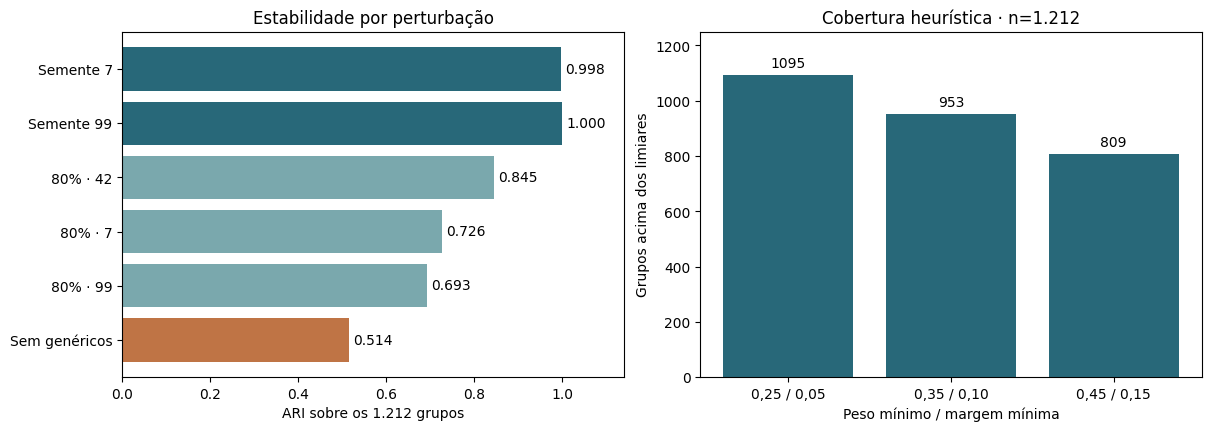

In [10]:
total_diag=len(diagnostico_n04)
display(pd.Series({"Trechos de desenvolvimento":total_diag,
    "Coincidência da regra N04 no trecho":diagnostico_n04["Regra N04 no excerto"].sum(),
    "Coincidência contextual por aspecto e offsets":diagnostico_n04["Contextual sobrepõe"].sum(),
    "Sem regra equivalente na taxonomia N04":diagnostico_n04["Regra N04 no excerto"].isna().sum()}).to_frame("Quantidade"))
assert len(grupos_casos)==9
exclusao=ctx_novo.loc[ctx_novo.Excerto.str.lower().eq("charging money")]
display(exclusao[["grupo_textual_id","Excerto","Aspecto","Objeto candidato"]].head(3))
print("Limites observáveis: ‘Could have been thicker’ e a menção de sabor exigem outra regra ou leitura.")
# Visualiza estabilidade e efeito da escolha do limiar, sem representar qualidade preditiva.
est=resultado["estabilidade"]
lim=resultado["limiares"]
fig,axs=plt.subplots(1,2,figsize=(12,4.2),layout="constrained")
labels=["Semente 7","Semente 99","80% · 42","80% · 7","80% · 99","Sem genéricos"]
axs[0].barh(labels,est.ARI_atribuicao_global,color=["#286879"]*2+["#7aa8ad"]*3+["#bf7445"])
axs[0].invert_yaxis()
axs[0].set(xlim=(0,1.14),xlabel="ARI sobre os 1.212 grupos",title="Estabilidade por perturbação")
axs[0].bar_label(axs[0].containers[0],fmt="%.3f",padding=3)
axs[1].bar(["0,25 / 0,05","0,35 / 0,10","0,45 / 0,15"],lim.grupos_sem_abstencao,color="#286879")
axs[1].set(ylim=(0,1250),xlabel="Peso mínimo / margem mínima",ylabel="Grupos acima dos limiares",
           title="Cobertura heurística · n=1.212")
axs[1].bar_label(axs[1].containers[0],padding=3)
plt.show()

In [11]:
# Coberturas pós-modelagem, no mesmo produto. A unidade é produto, não menção.
ctx_ids=set(ctx_novo.grupo_textual_id)
resumo_ml=prod_modelo.assign(
    Tema_acima_limiar=prod_modelo.grupos_sem_abstencao.gt(0),
    Contextual=prod_modelo.product_id.isin(pares_pg.loc[pares_pg.grupo_textual_id.isin(ctx_ids),"product_id"]))
quadro_perfis_ml=resumo_ml.groupby("perfil_completo").agg(
    Produtos=("product_id","size"),Com_tema_acima_limiar=("Tema_acima_limiar","sum"),
    Com_candidato_contextual=("Contextual","sum"))
assert quadro_perfis_ml.Produtos.sum()==1351
display(quadro_perfis_ml)
triagem_contextual=corpus.assign(Candidato=corpus.grupo_textual_id.isin(ctx_ids)).groupby("triagem_escrita").Candidato.agg(
    Grupos="size",Com_candidato="sum")
display(triagem_contextual)

,Produtos,Com_tema_acima_limiar,Com_candidato_contextual
perfil_completo,,,
A,212,164,151
Alta/baixa,241,194,188
Ausência,3,3,2
B,299,231,209
Baixa/baixa,330,277,232
Empate,228,186,172
Fora do recorte,38,29,23


,Grupos,Com_candidato
triagem_escrita,,
Escrita índica presente; idioma não confirmado,57,40
Sem escrita índica detectada; idioma não confirmado,1155,829


Cobertura por perfil e escrita é um diagnóstico do método. A composição por função muda o vocabulário, e triagem de escrita não confirma idioma nem acerto semântico.

## 3 — Dependências, anotação e avaliação futura

In [12]:
# Propriedade de separação das subamostras: nenhuma chave atravessa componentes.
checagens_split=[]
mapa_comp=comp.set_index('grupo_textual_id').componente
for seed in [42,7,99]:
    ids=np.unique(comp.componente);rng=np.random.default_rng(seed)
    ajuste=set(rng.choice(ids,size=int(.8*len(ids)),replace=False))
    a=set(comp.loc[comp.componente.isin(ajuste),'grupo_textual_id']);b=set(comp.grupo_textual_id)-a
    for chave,origem in [('product_id',vinculos_textuais),('review_id',contexto_reviews)]:
        ch_a=set(origem.loc[origem.grupo_textual_id.isin(a),chave]);ch_b=set(origem.loc[origem.grupo_textual_id.isin(b),chave])
        assert not ch_a & ch_b, 'Sobreposição de dependência: '+chave
        checagens_split.append({'Semente':seed,'Chave':chave,'Sobreposicao':len(ch_a & ch_b),'Grupos ajuste':len(a),'Grupos restantes':len(b)})
display(pd.DataFrame(checagens_split))
piloto=piloto_anotacao(corpus,vinculos_textuais,perfis,atribuicoes,comp)
assert piloto[['anotador_1','anotador_2','aspectos','adjudicacao']].isna().all().all()
display(piloto[['grupo_textual_id','status']].head())
print('Grupos no piloto, sem rótulos:',len(piloto))

,Semente,Chave,Sobreposicao,Grupos ajuste,Grupos restantes
0,42,product_id,0,967,245
1,42,review_id,0,967,245
2,7,product_id,0,969,243
3,7,review_id,0,969,243
4,99,product_id,0,967,245
5,99,review_id,0,967,245


,grupo_textual_id,status
6,TXT-000007,PENDENTE_ANOTACAO_HUMANA
9,TXT-000011,PENDENTE_ANOTACAO_HUMANA
13,TXT-000016,PENDENTE_ANOTACAO_HUMANA
14,TXT-000017,PENDENTE_ANOTACAO_HUMANA
24,TXT-000028,PENDENTE_ANOTACAO_HUMANA


Grupos no piloto, sem rótulos: 60


In [13]:
# Dependências adicionais para um protocolo futuro. Família candidata é uma barreira conservadora de divisão.
p_familia=perfis[["product_id","category_original","product_name","about_product_referencia"]].copy()
p_familia["nome_base"]=(p_familia.product_name.str.lower()
    .str.replace(r"\s*[-–,]?\s*(?:\([^()]{1,35}\)|(?:black|white|blue|red|rose gold|charcoal|ivory|grey|gray))\s*$","",regex=True)
    .str.replace(r"[^a-z0-9]+"," ",regex=True).str.strip())
assert p_familia.nome_base.ne("").all()
fam = pares_pg.merge(p_familia,on="product_id",validate="many_to_one")
arestas=[]
for chave in ["nome_base","about_product_referencia"]:
    for _,d in fam.groupby(["category_original",chave]):
        if d.product_id.nunique()<2: continue
        ids=d.grupo_textual_id.unique()
        arestas.extend((ids[0],v) for v in ids[1:])
arestas_familia=pd.DataFrame(arestas,columns=["grupo_a","grupo_b"]).drop_duplicates()
arestas_split=pd.concat([pares_proximos.loc[pares_proximos.cosseno.ge(.80),["grupo_a","grupo_b"]],
                         arestas_familia],ignore_index=True).drop_duplicates()
comp_futuro=componentes(corpus,vinculos_textuais,contexto_reviews,arestas_split)
componente_de=comp_futuro.set_index("grupo_textual_id").componente
conhecidos=set(piloto.grupo_textual_id)|set(grupos_casos.grupo_textual_id)|set(exemplos.grupo_textual_id)|set(ids_desenvolvimento)
dev_comp=set(componente_de.loc[sorted(conhecidos)])
restantes=np.array(sorted(set(componente_de)-dev_comp))
restantes=np.random.default_rng(42).permutation(restantes)
n_val=round(.15*comp_futuro.componente.nunique())
valid_comp=set(restantes[:n_val])
teste_comp=set(restantes[n_val:2*n_val])
particao=comp_futuro.copy()
particao["partição proposta"]=np.select(
    [particao.componente.isin(teste_comp),particao.componente.isin(valid_comp)],
    ["Reserva teste","Reserva validação"],default="Desenvolvimento")
assert particao.loc[particao.grupo_textual_id.isin(conhecidos),"partição proposta"].eq("Desenvolvimento").all()
assert particao.groupby("componente")["partição proposta"].nunique().eq(1).all()
for chave,links in [("product_id",vinculos_textuais),("ocorrencia_id",vinculos_textuais),("review_id",contexto_reviews)]:
    ver=links[[chave,"grupo_textual_id"]].merge(particao,on="grupo_textual_id",validate="many_to_one")
    assert ver.groupby(chave)["partição proposta"].nunique().eq(1).all(),chave
assert all(componente_de[a]==componente_de[b] for a,b in arestas_split.itertuples(index=False,name=None))
assert componente_de[grupos_casos.set_index("product_id").at["B09JS562TP","grupo_textual_id"]]==componente_de[
    pares_pg.loc[pares_pg.product_id.eq("B09JS94MBV"),"grupo_textual_id"].iloc[0]]
reserva=particao.groupby("partição proposta").agg(Grupos=("grupo_textual_id","size"),Componentes=("componente","nunique"))
display(reserva)
print("Componentes históricos:",comp.componente.nunique(),"| Componentes da proposta:",comp_futuro.componente.nunique(),
      "| Arestas de família candidata:",len(arestas_familia))
# Pacote cego de desenvolvimento. Os dois anotadores recebem formulários separados, sem perfis ou predições.
sem_lexico=regex_12.loc[~regex_12[list(taxonomia_n04)].any(axis=1),"grupo_textual_id"]
sem_lexico=sem_lexico.loc[sem_lexico.map(particao.set_index("grupo_textual_id")["partição proposta"]).eq("Desenvolvimento")]
ids_piloto=set(piloto.grupo_textual_id)|set(grupos_casos.grupo_textual_id)|set(sem_lexico.sort_values().head(5))
material=corpus.loc[corpus.grupo_textual_id.isin(ids_piloto),["grupo_textual_id","review_title","review_content"]]
campos_humanos=["anotador","data","versao_guia","campo","inicio","fim","excerto","objeto","aspecto","polaridade","idioma","ambiguidade","abstencao"]
formulario=material.assign(**{c:pd.NA for c in campos_humanos})
assert formulario[campos_humanos].isna().all().all()
print("Grupos no piloto ampliado:",len(formulario),"| sem candidatos lexicais no suplemento:",min(len(sem_lexico),5))

,Grupos,Componentes
partição proposta,,
Desenvolvimento,854,814
Reserva teste,181,175
Reserva validação,177,175


Componentes históricos: 1181 | Componentes da proposta: 1164 | Arestas de família candidata: 26
Grupos no piloto ampliado: 73 | sem candidatos lexicais no suplemento: 5


A proposta reserva componentes para uma avaliação futura, com casos já inspecionados em desenvolvimento. O corpus inteiro participou dos diagnósticos e ajustes exploratórios do NMF histórico. As reservas atuais servem para simular a divisão e organizar anotação futura. Uma avaliação independente deste experimento exige novos dados mantidos fechados até fixar regras, modelo e limiares. Quase duplicatas abaixo dos cortes, paráfrases, variantes não detectadas e dependência por autores continuam possíveis.

## 4 — Hierarquia como baseline funcional

In [14]:
# Baseline auxiliar para navegação. Cada regra vem do nível 1 oficial.
categorias=can["categorias"].copy()
macro_por_topo={"Electronics":"Eletrônicos","Computers&Accessories":"Informática",
                "Home&Kitchen":"Casa e cozinha","OfficeProducts":"Escritório"}
macro_aux=categorias[["categoria_id","category_original","categoria_nivel_1"]].copy()
macro_aux["Macro auxiliar"]=macro_aux.categoria_nivel_1.map(macro_por_topo).fillna("Abstenção")
assert len(macro_aux)==211 and macro_aux.categoria_id.is_unique
display(macro_aux.groupby("Macro auxiliar").categoria_id.nunique().rename("Caminhos").to_frame())
print("Macro auxiliar apenas reproduz recortes da hierarquia. Sem rótulos e sem decisão de substituir caminhos.")

,Caminhos
Macro auxiliar,
Abstenção,6
Casa e cozinha,72
Eletrônicos,62
Escritório,14
Informática,57


Macro auxiliar apenas reproduz recortes da hierarquia. Sem rótulos e sem decisão de substituir caminhos.


## 5 — Decisão de uso e maturidade

| N03 | N04 | N05 | Sustentação e uso |
|---|---|---|---|
| Cabos A/B a INR 349 | Conectores distintos e carga do aparelho | Tema de cabos organiza a busca. Expressão contextual pode localizar carga no dispositivo | Exploratória. Conferir SKU e objeto no trecho |
| Fones de mesmo preço e perfis sensíveis | Elogios ao som, ressalvas a graves, material e duração | Um bloco reúne candidatos com sinais opostos. Peso temático não os distingue | Leitura local para priorizar especificação e suporte |
| Ferros com mesmo desconto | Facilidade, peso e dano na entrega | Menção contextual a entrega separa parte da evidência logística | Candidatos precisam de avaliação de objeto |
| Celular sensível e purificador A persistente | Autonomia, FM, instalação, sabor, entrada de água | Regras recuperam parte do contexto. Sabor e referências implícitas exigem leitura | Triagem e coleta técnica. Sem frequência de defeitos |
| Diferenças de função entre categorias | Frequências dependem de caminho e definição lexical | Temas seguem parcialmente a hierarquia e têm sensibilidade ao vocabulário | Preservar hierarquia e perfis. Usar temas em QA |

Cobertura, grupos e menções literais versionadas estão disponíveis para descrição quantitativa. Pesos, temas, similaridades e candidatos contextuais são exploratórios. Aspectos, objetos e polaridade automatizados dependem de anotação, avaliação por função e aprovação. Frequências de reclamações, satisfação e incidência de defeito ficam fora da camada executiva nesta entrega. K01–K12 e CI01–CI06 conservam as definições vigentes.

In [15]:
# Checkpoints calculados. Referências históricas são verificadas externamente na auditoria.
assert resultado["parametros"]["numero_ajustes_nmf"]==13
assert len(resultado["metricas"])==9 and len(resultado["estabilidade"])==6
assert len(atribuicoes)==1212 and atribuicoes.grupo_textual_id.is_unique
assert {"no","not","nor","never"}.isdisjoint(resultado["vectorizer"].stop_words)
assert resultado["x"].shape[0]==len(corpus)
assert np.allclose(resultado["pesos"].drop(columns="grupo_textual_id").sum(axis=1),1)
assert len(piloto)==60
if saida is not None:
    artefatos={"metricas_nmf.csv":resultado["metricas"],"estabilidade_nmf.csv":resultado["estabilidade"],
        "temas_nmf.csv":resultado["temas"],"atribuicoes_grupos_nmf.csv":atribuicoes,
        "pesos_grupos_nmf.csv":resultado["pesos"],"exemplos_temas_integrais.csv":resultado["exemplos"],
        "sensibilidade_limiares.csv":resultado["limiares"],"sobreposicao_baseline_nmf.csv":sobreposicao.reset_index(),
        "contrastes_temas_caminho.csv":contrastes_modelo,"produtos_temas_exploratorios.csv":prod_modelo,
        "diagnostico_escrita_modelo.csv":diagnostico_escrita,"componentes_modelagem.csv":comp,
        "validacao_subamostras.csv":pd.DataFrame(checagens_split),"casos_criticos_nmf.csv":casos_criticos,
        "piloto_historico_recalculado.csv":piloto,"candidatos_contextuais.csv":ctx_novo,
        "diagnostico_trechos_n04.csv":diagnostico_n04,"casos_n03_n04.csv":casos_ml,
        "comparacao_metodos.csv":comparacao_metodos.reset_index(names="Aspecto"),
        "particao_proposta.csv":particao,"macro_auxiliar.csv":macro_aux,
        "piloto_anotador_1_PENDENTE.csv":formulario,"piloto_anotador_2_PENDENTE.csv":formulario}
    for nome,d in artefatos.items():
        salvar_csv(d,saida,nome)
    parametros=resultado["parametros"]|{"python":platform.python_version(),"pandas":pd.__version__,
        "numpy":np.__version__,"scipy":scipy.__version__,"sklearn":sklearn.__version__,
        "contextuais":"v1, regras do notebook","particao":"seed 42, famílias candidatas e cosseno ≥0,80"}
    (saida/"parametros_experimento.json").write_text(json.dumps(parametros,ensure_ascii=False,indent=2),encoding="utf8")
    np.savez_compressed(saida/"estado_numerico_nmf.npz",componentes=resultado["modelo"].components_,
                       idf=resultado["vectorizer"].idf_)
    (saida/"vocabulario_tfidf.json").write_text(json.dumps(resultado["vectorizer"].get_feature_names_out().tolist()),encoding="utf8")
print("Validação concluída. Exportação experimental:", "backup autorizado" if saida is not None else "desativada")

Validação concluída. Exportação experimental: backup autorizado
